In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.cluster.hierarchy as sch

from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
clients = pd.read_csv("clients.csv")
properties = pd.read_csv("properties.csv")

print("Clients dataset shape:", clients.shape)
print("Properties dataset shape:", properties.shape)

Clients dataset shape: (2000, 12)
Properties dataset shape: (10000, 9)


In [4]:
print("CLIENTS DATASET")
clients.info()

print("\nPROPERTIES DATASET")
properties.info()

CLIENTS DATASET
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   client_id            2000 non-null   str  
 1   client_type          2000 non-null   str  
 2   first_name           2000 non-null   str  
 3   last_name            2000 non-null   str  
 4   date_of_birth        2000 non-null   str  
 5   gender               2000 non-null   str  
 6   country              2000 non-null   str  
 7   region               2000 non-null   str  
 8   acquisition_purpose  2000 non-null   str  
 9   satisfaction_score   2000 non-null   int64
 10  loan_applied         2000 non-null   str  
 11  referral_channel     2000 non-null   str  
dtypes: int64(1), str(11)
memory usage: 312.6 KB

PROPERTIES DATASET
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
--- 

In [5]:
print("Missing values in Properties dataset:")
print(properties.isnull().sum())

Missing values in Properties dataset:
listing_id             0
tower_number           0
transaction_date       0
unit_category          0
unit_number            0
floor_area_sqft        0
sale_price             0
listing_status         0
client_ref          2695
dtype: int64


In [6]:
print("Total missing values in Clients:", clients.isnull().sum().sum())
print("Total missing values in Properties:", properties.isnull().sum().sum())

Total missing values in Clients: 0
Total missing values in Properties: 2695


In [7]:
# 1. Check duplicate records
print("Duplicate client rows:", clients.duplicated().sum())
print("Duplicate client IDs:", clients["client_id"].duplicated().sum())

print("Duplicate property rows:", properties.duplicated().sum())
print("Duplicate listing IDs:", properties["listing_id"].duplicated().sum())

# 2. Check category values
print("\nClient Types:")
print(clients["client_type"].value_counts())

print("\nAcquisition Purposes:")
print(clients["acquisition_purpose"].value_counts())

print("\nProperty Categories:")
print(properties["unit_category"].value_counts())

# 3. Check date formats
print("\nClient Date Examples:")
print(clients["date_of_birth"].head())

print("\nProperty Date Examples:")
print(properties["transaction_date"].head())

# 4. Check sale price examples
print("\nSale Price Examples:")
print(properties["sale_price"].head())

Duplicate client rows: 0
Duplicate client IDs: 0
Duplicate property rows: 0
Duplicate listing IDs: 0

Client Types:
client_type
Individual    1897
Company        103
Name: count, dtype: int64

Acquisition Purposes:
acquisition_purpose
Home          1385
Investment     615
Name: count, dtype: int64

Property Categories:
unit_category
Apartment    8547
Office       1453
Name: count, dtype: int64

Client Date Examples:
0    05-11-1968
1    11/26/1962
2    04-07-1959
3    11/25/1959
4     2/28/1976
Name: date_of_birth, dtype: str

Property Date Examples:
0    01-01-2024
1    01-01-2024
2    01-01-2024
3    01-01-2024
4    01-01-2024
Name: transaction_date, dtype: str

Sale Price Examples:
0    $300,385.62
1    $208,930.81
2    $218,585.92
3    $246,172.68
4    $212,265.67
Name: sale_price, dtype: str


In [8]:
# Keep original data safe
clients_clean = clients.copy()
properties_clean = properties.copy()

# 1. Remove duplicate records
clients_clean = clients_clean.drop_duplicates(subset="client_id")
properties_clean = properties_clean.drop_duplicates(subset="listing_id")

# 2. Standardize text columns
client_text_cols = [
    "client_type", "gender", "country", "region",
    "acquisition_purpose", "loan_applied", "referral_channel"
]

property_text_cols = ["unit_category", "listing_status"]

for col in client_text_cols:
    clients_clean[col] = (
        clients_clean[col].astype("string").str.strip().str.title()
    )

for col in property_text_cols:
    properties_clean[col] = (
        properties_clean[col].astype("string").str.strip().str.title()
    )

# 3. Convert dates
clients_clean["date_of_birth"] = pd.to_datetime(
    clients_clean["date_of_birth"],
    format="mixed",
    errors="coerce"
)

properties_clean["transaction_date"] = pd.to_datetime(
    properties_clean["transaction_date"],
    format="mixed",
    errors="coerce"
)

# 4. Calculate buyer age
today = pd.Timestamp.today().normalize()

clients_clean["age"] = (
    (today - clients_clean["date_of_birth"]).dt.days / 365.25
).round(1)

# 5. Convert sale price into numeric values
properties_clean["sale_price"] = pd.to_numeric(
    properties_clean["sale_price"]
    .astype("string")
    .str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

# 6. Check the cleaned data
print("Cleaning completed!")

print("Clients shape:", clients_clean.shape)
print("Properties shape:", properties_clean.shape)

print("\nMissing values in clients:")
print(clients_clean.isnull().sum())

print("\nMissing values in properties:")
print(properties_clean.isnull().sum())

Cleaning completed!
Clients shape: (2000, 13)
Properties shape: (10000, 9)

Missing values in clients:
client_id              0
client_type            0
first_name             0
last_name              0
date_of_birth          0
gender                 0
country                0
region                 0
acquisition_purpose    0
satisfaction_score     0
loan_applied           0
referral_channel       0
age                    0
dtype: int64

Missing values in properties:
listing_id             0
tower_number           0
transaction_date       0
unit_category          0
unit_number            0
floor_area_sqft        0
sale_price             0
listing_status         0
client_ref          2695
dtype: int64


,client_id,client_type,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel,age
count,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000.000000,2000,2000,2000.000000
unique,2000,2,337,224,NaN,2,10,57,2,NaN,2,3,NaN
top,C0001,Individual,Carl,Co,NaN,M,Usa,California,Home,NaN,No,Website,NaN
freq,1,1897,24,103,NaN,1012,1538,633,1385,NaN,1264,1103,NaN
mean,NaN,NaN,NaN,NaN,1970-05-26 02:22:33.600000,NaN,NaN,NaN,NaN,3.029000,NaN,NaN,56.459650
min,NaN,NaN,NaN,NaN,1931-02-13 00:00:00,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,25.900000
25%,NaN,NaN,NaN,NaN,1955-12-21 12:00:00,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,41.700000
50%,NaN,NaN,NaN,NaN,1969-10-25 00:00:00,NaN,NaN,NaN,NaN,3.000000,NaN,NaN,57.000000
75%,NaN,NaN,NaN,NaN,1985-02-19 18:00:00,NaN,NaN,NaN,NaN,4.000000,NaN,NaN,70.900000
max,NaN,NaN,NaN,NaN,2000-12-19 00:00:00,NaN,NaN,NaN,NaN,5.000000,NaN,NaN,95.700000


,listing_id,tower_number,transaction_date,unit_category,unit_number,floor_area_sqft,sale_price,listing_status,client_ref
count,10000.000000,10000.000000,10000,10000,10000.00000,10000.000000,10000.0,10000,7305
unique,NaN,NaN,NaN,2,NaN,NaN,<NA>,2,2000
top,NaN,NaN,NaN,Apartment,NaN,NaN,<NA>,Sold,C0005
freq,NaN,NaN,NaN,8547,NaN,NaN,<NA>,7305,13
mean,105898.277400,10.370100,2024-11-07 13:03:47.520000,NaN,28.99920,1139.941412,344374.678683,NaN,NaN
min,1002.000000,1.000000,2024-01-01 00:00:00,NaN,1.00000,410.710000,97402.8,NaN,NaN
25%,50389.750000,5.000000,2024-05-01 00:00:00,NaN,15.00000,782.200000,232173.6425,NaN,NaN
50%,100404.500000,10.000000,2024-10-01 00:00:00,NaN,29.00000,1110.880000,330680.845,NaN,NaN
75%,150411.250000,15.000000,2025-05-01 00:00:00,NaN,43.00000,1499.000000,448852.575,NaN,NaN
max,990026.000000,20.000000,2025-12-01 00:00:00,NaN,70.00000,1957.160000,736652.27,NaN,NaN


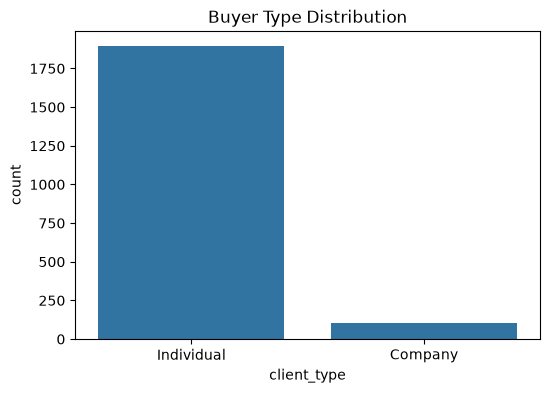

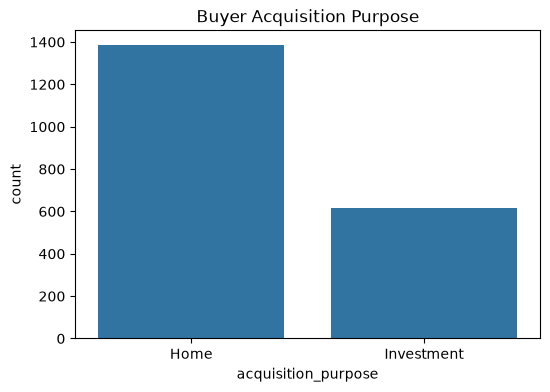

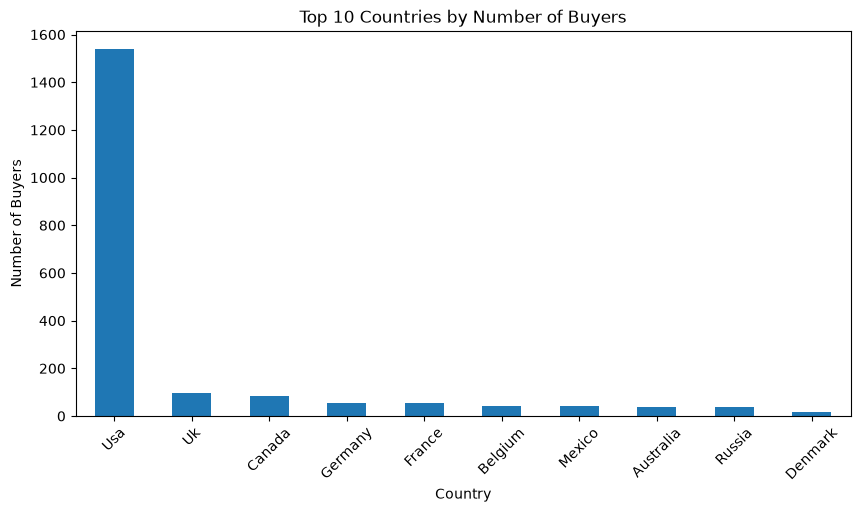

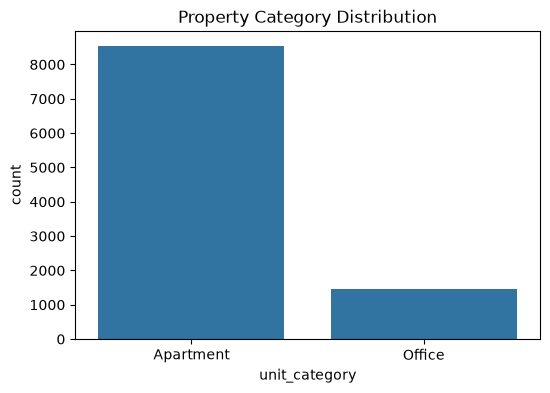

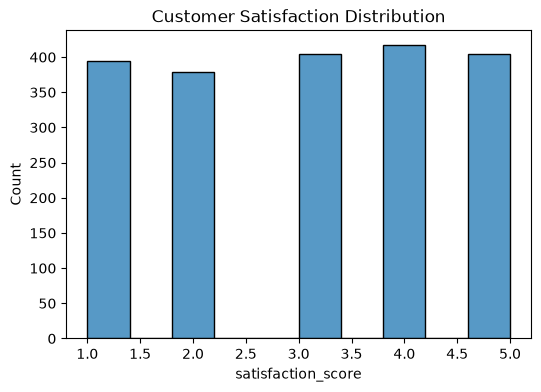

In [9]:
# Basic statistical summary
display(clients_clean.describe(include="all"))
display(properties_clean.describe(include="all"))

# Buyer type distribution
plt.figure(figsize=(6,4))
sns.countplot(data=clients_clean, x="client_type")
plt.title("Buyer Type Distribution")
plt.show()

# Acquisition purpose
plt.figure(figsize=(6,4))
sns.countplot(data=clients_clean, x="acquisition_purpose")
plt.title("Buyer Acquisition Purpose")
plt.show()

# Country-wise buyers
plt.figure(figsize=(10,5))
clients_clean["country"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Countries by Number of Buyers")
plt.xlabel("Country")
plt.ylabel("Number of Buyers")
plt.xticks(rotation=45)
plt.show()

# Property category
plt.figure(figsize=(6,4))
sns.countplot(data=properties_clean, x="unit_category")
plt.title("Property Category Distribution")
plt.show()

# Satisfaction score
plt.figure(figsize=(6,4))
sns.histplot(clients_clean["satisfaction_score"], bins=10)
plt.title("Customer Satisfaction Distribution")
plt.show()

In [10]:
# Match properties to clients using their IDs
clients_clean["client_id"] = clients_clean["client_id"].astype("string").str.strip()
properties_clean["client_ref"] = properties_clean["client_ref"].astype("string").str.strip()

property_summary = (
    properties_clean.dropna(subset=["client_ref"])
    .groupby("client_ref")
    .agg(
        property_count=("listing_id", "count"),
        average_sale_price=("sale_price", "mean"),
        average_floor_area=("floor_area_sqft", "mean")
    )
    .reset_index()
    .rename(columns={"client_ref": "client_id"})
)

buyer_data = clients_clean.merge(
    property_summary,
    on="client_id",
    how="left"
)

# Buyers without linked properties receive zero for these aggregate measures
buyer_data[["property_count", "average_sale_price", "average_floor_area"]] = (
    buyer_data[["property_count", "average_sale_price", "average_floor_area"]]
    .fillna(0)
)

print("Buyer data shape:", buyer_data.shape)
display(buyer_data.head())

Buyer data shape: (2000, 16)


,client_id,client_type,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel,age,property_count,average_sale_price,average_floor_area
0,C0001,Individual,Kareem,Liu,1968-05-11,F,Usa,California,Home,4,Yes,Website,58.5,4,311691.18,983.885000
1,C0002,Individual,Trystan,Oconnor,1962-11-26,M,Usa,California,Home,1,No,Website,64.0,5,368219.186,1187.942000
2,C0003,Individual,Kale,Gay,1959-04-07,M,Usa,California,Home,4,Yes,Agency,67.6,5,332291.518,1058.110000
3,C0004,Individual,Russell,Gross,1959-11-25,M,Usa,California,Home,5,No,Website,67.0,6,268043.918333,937.103333
4,C0005,Company,Marleez,Co,1976-02-28,M,Usa,California,Investment,5,No,Website,50.7,13,281029.644615,927.296154


In [11]:
# Select categorical columns
categorical_cols = [
    "client_type", "region", "acquisition_purpose",
    "referral_channel", "country", "gender", "loan_applied"
]

# Select numerical columns
numeric_cols = [
    "age", "satisfaction_score",
    "property_count", "average_sale_price", "average_floor_area"
]

# Handle any remaining missing feature values
for col in categorical_cols:
    buyer_data[col] = buyer_data[col].fillna("Unknown")

for col in numeric_cols:
    buyer_data[col] = buyer_data[col].fillna(buyer_data[col].median())

# One-hot encoding
encoded_data = pd.get_dummies(
    buyer_data[categorical_cols],
    dtype=int
)

# Scale numerical features
scaler = StandardScaler()

scaled_numeric = pd.DataFrame(
    scaler.fit_transform(buyer_data[numeric_cols]),
    columns=numeric_cols,
    index=buyer_data.index
)

# Combine encoded and scaled features
X = pd.concat([scaled_numeric, encoded_data], axis=1)

print("Final machine learning data shape:", X.shape)
display(X.head())

Final machine learning data shape: (2000, 83)


,age,satisfaction_score,property_count,average_sale_price,average_floor_area,client_type_Company,client_type_Individual,region_Alberta,region_Arizona,region_Baja California,...,country_France,country_Germany,country_Mexico,country_Russia,country_Uk,country_Usa,gender_F,gender_M,loan_applied_No,loan_applied_Yes
0,0.117631,0.687089,0.413942,-0.507841,-0.744060,0,1,0,0,0,...,0,0,0,0,0,1,1,0,0,1
1,0.434719,-1.435740,1.605141,0.303126,0.184030,0,1,0,0,0,...,0,0,0,0,0,1,0,1,1,0
2,0.642267,0.687089,1.605141,-0.212303,-0.406470,0,1,0,0,0,...,0,0,0,0,0,1,0,1,0,1
3,0.607676,1.394698,2.796340,-1.134018,-0.956832,0,1,0,0,0,...,0,0,0,0,0,1,0,1,1,0
4,-0.332057,1.394698,11.134734,-0.947721,-1.001437,1,0,0,0,0,...,0,0,0,0,0,1,0,1,1,0


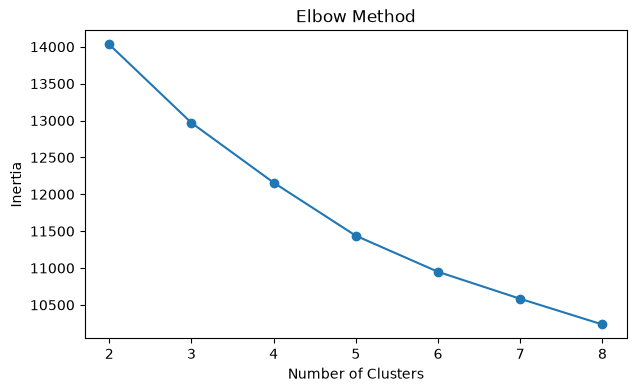

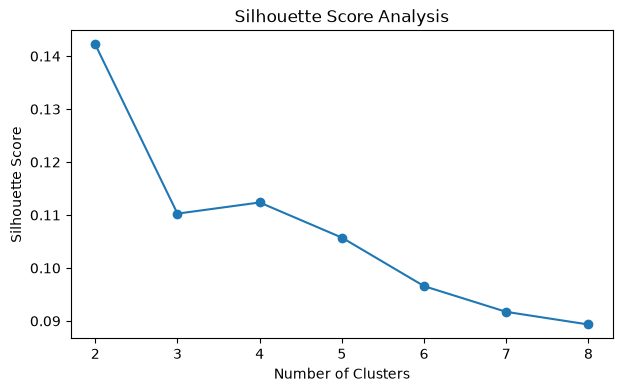

,Clusters,Inertia,Silhouette Score
0,2,14030.919879,0.142197
1,3,12968.385797,0.110264
2,4,12157.634148,0.112370
3,5,11437.816494,0.105736
4,6,10948.653856,0.096575
5,7,10582.766137,0.091716
6,8,10234.429015,0.089330


Best cluster count based on Silhouette Score: 2


In [12]:
inertia_values = []
silhouette_values = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)

    inertia_values.append(model.inertia_)
    silhouette_values.append(silhouette_score(X, labels))

# Elbow Method
plt.figure(figsize=(7,4))
plt.plot(list(k_values), inertia_values, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

# Silhouette Score
plt.figure(figsize=(7,4))
plt.plot(list(k_values), silhouette_values, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Analysis")
plt.show()

# Display scores
score_table = pd.DataFrame({
    "Clusters": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(score_table)

best_k = score_table.loc[
    score_table["Silhouette Score"].idxmax(), "Clusters"
]

print("Best cluster count based on Silhouette Score:", best_k)

In [13]:
kmeans = KMeans(
    n_clusters=int(best_k),
    random_state=42,
    n_init=10
)

buyer_data["KMeans_Cluster"] = kmeans.fit_predict(X)

print("K-Means clustering completed!")

display(
    buyer_data["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)

K-Means clustering completed!


KMeans_Cluster
0     807
1    1193
Name: count, dtype: int64

In [14]:
hierarchical = AgglomerativeClustering(
    n_clusters=int(best_k),
    linkage="ward"
)

buyer_data["Hierarchical_Cluster"] = hierarchical.fit_predict(X)

print("Hierarchical clustering completed!")

print(
    "Hierarchical Silhouette Score:",
    silhouette_score(X, buyer_data["Hierarchical_Cluster"])
)

Hierarchical clustering completed!
Hierarchical Silhouette Score: 0.13298272085638985


In [15]:
cluster_profile = buyer_data.groupby("KMeans_Cluster").agg(
    Total_Buyers=("client_id", "count"),
    Average_Age=("age", "mean"),
    Average_Satisfaction=("satisfaction_score", "mean"),
    Average_Properties=("property_count", "mean"),
    Average_Sale_Price=("average_sale_price", "mean"),
    Investment_Buyers=("acquisition_purpose",
                       lambda x: (x == "Investment").sum()),
    Home_Buyers=("acquisition_purpose",
                 lambda x: (x == "Home").sum())
).round(2)

display(cluster_profile)

# Categorical characteristics of each cluster
for cluster in sorted(buyer_data["KMeans_Cluster"].unique()):
    print("\nCLUSTER", cluster)

    subset = buyer_data[
        buyer_data["KMeans_Cluster"] == cluster
    ]

    for col in [
        "client_type", "country", "region",
        "acquisition_purpose", "loan_applied"
    ]:
        print("\n", col)
        print(subset[col].value_counts().head(5))

,Total_Buyers,Average_Age,Average_Satisfaction,Average_Properties,Average_Sale_Price,Investment_Buyers,Home_Buyers
KMeans_Cluster,,,,,,,
0,807,55.63,3.05,3.47,414534.61,245,562
1,1193,57.02,3.02,3.77,301467.3,370,823



CLUSTER 0

 client_type
client_type
Individual    761
Company        46
Name: count, dtype: int64[pyarrow]

 country
country
Usa        612
Uk          42
Canada      36
Germany     24
France      24
Name: count, dtype: int64[pyarrow]

 region
region
California    251
Nevada         61
Arizona        46
Colorado       40
Washington     36
Name: count, dtype: int64[pyarrow]

 acquisition_purpose
acquisition_purpose
Home          562
Investment    245
Name: count, dtype: int64[pyarrow]

 loan_applied
loan_applied
No     516
Yes    291
Name: count, dtype: int64[pyarrow]

CLUSTER 1

 client_type
client_type
Individual    1136
Company         57
Name: count, dtype: int64[pyarrow]

 country
country
Usa        926
Uk          53
Canada      49
Germany     32
France      29
Name: count, dtype: int64[pyarrow]

 region
region
California    382
Nevada         82
Colorado       78
Oregon         62
Arizona        62
Name: count, dtype: int64[pyarrow]

 acquisition_purpose
acquisition_purpose
Home

In [16]:
# Save buyer segmentation results
buyer_data.to_csv("buyer_segmentation_results.csv", index=False)

# Save cluster summary
cluster_profile.to_csv("cluster_profile.csv")

print("Project results saved successfully!")

Project results saved successfully!


In [17]:
%%writefile app.py

import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(
    page_title="Real Estate Buyer Intelligence",
    page_icon="🏡",
    layout="wide"
)

# Load data
@st.cache_data
def load_data():
    return pd.read_csv("buyer_segmentation_results.csv")

df = load_data()

# Dashboard title
st.title("🏡 Real Estate Buyer Segmentation")
st.caption("Machine Learning Based Buyer & Investment Intelligence")

# Sidebar filters
st.sidebar.title("Dashboard Filters")

def filter_options(column):
    return sorted(df[column].dropna().unique().tolist())

country = st.sidebar.multiselect(
    "Select Country", filter_options("country")
)

region = st.sidebar.multiselect(
    "Select Region", filter_options("region")
)

purpose = st.sidebar.multiselect(
    "Acquisition Purpose", filter_options("acquisition_purpose")
)

buyer_type = st.sidebar.multiselect(
    "Buyer Type", filter_options("client_type")
)

cluster = st.sidebar.multiselect(
    "Buyer Segment", filter_options("KMeans_Cluster")
)

# Apply filters
filtered = df.copy()

if country:
    filtered = filtered[filtered["country"].isin(country)]

if region:
    filtered = filtered[filtered["region"].isin(region)]

if purpose:
    filtered = filtered[
        filtered["acquisition_purpose"].isin(purpose)
    ]

if buyer_type:
    filtered = filtered[
        filtered["client_type"].isin(buyer_type)
    ]

if cluster:
    filtered = filtered[
        filtered["KMeans_Cluster"].astype(str).isin(cluster)
    ]

st.sidebar.caption(f"Showing {len(filtered):,} buyers")

if filtered.empty:
    st.warning("No buyers match the selected filters.")
    st.stop()

# KPI cards
st.subheader("Buyer Segmentation Overview")

c1, c2, c3, c4 = st.columns(4)

c1.metric("Total Buyers", f"{len(filtered):,}")

c2.metric(
    "Investment Buyers",
    f"{(filtered['acquisition_purpose'] == 'Investment').sum():,}"
)

c3.metric(
    "Average Age",
    f"{filtered['age'].mean():.1f}"
)

c4.metric(
    "Buyer Segments",
    filtered["KMeans_Cluster"].nunique()
)

st.divider()

# Tabs
tab1, tab2, tab3, tab4 = st.tabs([
    "📊 Overview",
    "💰 Investor Behaviour",
    "🌍 Geographic Analysis",
    "👥 Segment Insights"
])

# TAB 1: OVERVIEW
with tab1:
    left, right = st.columns(2)

    with left:
        cluster_counts = (
            filtered["KMeans_Cluster"]
            .astype(str)
            .value_counts()
            .rename_axis("Cluster")
            .reset_index(name="Buyers")
        )

        fig = px.pie(
            cluster_counts,
            names="Cluster",
            values="Buyers",
            hole=0.45,
            title="Buyer Distribution by Cluster"
        )

        st.plotly_chart(fig, use_container_width=True)

    with right:
        purpose_counts = (
            filtered["acquisition_purpose"]
            .value_counts()
            .rename_axis("Purpose")
            .reset_index(name="Buyers")
        )

        fig = px.bar(
            purpose_counts,
            x="Purpose",
            y="Buyers",
            color="Purpose",
            title="Home vs Investment Buyers",
            text="Buyers"
        )

        st.plotly_chart(fig, use_container_width=True)

    st.subheader("Buyer Age Distribution")

    fig = px.histogram(
        filtered,
        x="age",
        color="client_type",
        nbins=20,
        title="Age Distribution by Buyer Type"
    )

    st.plotly_chart(fig, use_container_width=True)


# TAB 2: INVESTOR BEHAVIOUR
with tab2:
    investment = filtered[
        filtered["acquisition_purpose"] == "Investment"
    ]

    st.metric("Total Investment Buyers", len(investment))

    if not investment.empty:
        fig = px.histogram(
            investment,
            x="KMeans_Cluster",
            color="client_type",
            title="Investment Buyers Across Clusters",
            barmode="group"
        )

        st.plotly_chart(fig, use_container_width=True)

        fig = px.scatter(
            investment,
            x="property_count",
            y="average_sale_price",
            color="KMeans_Cluster",
            hover_data=[
                "client_type",
                "country",
                "region"
            ],
            title="Property Activity vs Average Sale Price",
            labels={
                "property_count": "Number of Linked Properties",
                "average_sale_price": "Average Sale Price"
            }
        )

        st.plotly_chart(fig, use_container_width=True)
    else:
        st.info("No investment buyers match these filters.")


# TAB 3: GEOGRAPHIC ANALYSIS
with tab3:
    left, right = st.columns(2)

    with left:
        country_counts = (
            filtered["country"]
            .value_counts()
            .head(10)
            .rename_axis("Country")
            .reset_index(name="Buyers")
        )

        fig = px.bar(
            country_counts,
            x="Country",
            y="Buyers",
            title="Top 10 Countries by Buyers",
            color="Buyers"
        )

        st.plotly_chart(fig, use_container_width=True)

    with right:
        region_counts = (
            filtered["region"]
            .value_counts()
            .head(10)
            .rename_axis("Region")
            .reset_index(name="Buyers")
        )

        fig = px.bar(
            region_counts,
            x="Buyers",
            y="Region",
            orientation="h",
            title="Top 10 Regions by Buyers",
            color="Buyers"
        )

        st.plotly_chart(fig, use_container_width=True)


# TAB 4: SEGMENT INSIGHTS
with tab4:
    st.subheader("Cluster-wise Buyer Profile")

    profile = filtered.groupby("KMeans_Cluster").agg(
        Total_Buyers=("client_id", "count"),
        Average_Age=("age", "mean"),
        Average_Satisfaction=("satisfaction_score", "mean"),
        Average_Properties=("property_count", "mean"),
        Average_Sale_Price=("average_sale_price", "mean")
    ).round(2).reset_index()

    st.dataframe(profile, use_container_width=True)

    fig = px.bar(
        profile,
        x="KMeans_Cluster",
        y="Total_Buyers",
        color="KMeans_Cluster",
        title="Number of Buyers in Each Cluster",
        text="Total_Buyers"
    )

    st.plotly_chart(fig, use_container_width=True)

    st.subheader("Buyer Records")

    st.dataframe(
        filtered,
        use_container_width=True,
        hide_index=True
    )

# Download filtered data
st.divider()

csv = filtered.to_csv(index=False).encode("utf-8")

st.download_button(
    label="⬇️ Download Filtered Buyer Data",
    data=csv,
    file_name="filtered_buyer_data.csv",
    mime="text/csv"
)

st.success("Interactive dashboard loaded successfully!")

Overwriting app.py


In [18]:
import os
print(os.getcwd())

C:\Users\abc\UM project2


In [19]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\abc\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [20]:
# 1. Compare clustering performance
print("K-MEANS CLUSTERING")
print("------------------")
display(score_table)

print("\nHIERARCHICAL CLUSTERING")
print("-----------------------")
print(
    "Silhouette Score:",
    silhouette_score(X, buyer_data["Hierarchical_Cluster"])
)

# 2. Number of buyers in each K-Means cluster
print("\nBUYERS IN EACH K-MEANS CLUSTER")
display(
    buyer_data["KMeans_Cluster"].value_counts().sort_index()
)

# 3. Number of buyers in each Hierarchical cluster
print("\nBUYERS IN EACH HIERARCHICAL CLUSTER")
display(
    buyer_data["Hierarchical_Cluster"].value_counts().sort_index()
)

# 4. Final buyer profile
print("\nK-MEANS CLUSTER PROFILE")
display(cluster_profile)

# 5. Final dataset information
print("\nFINAL DATASET INFORMATION")
print("Total buyers:", len(buyer_data))
print("Total features used:", X.shape[1])
print("Missing values in buyer data:", buyer_data.isnull().sum().sum())

K-MEANS CLUSTERING
------------------


,Clusters,Inertia,Silhouette Score
0,2,14030.919879,0.142197
1,3,12968.385797,0.110264
2,4,12157.634148,0.112370
3,5,11437.816494,0.105736
4,6,10948.653856,0.096575
5,7,10582.766137,0.091716
6,8,10234.429015,0.089330



HIERARCHICAL CLUSTERING
-----------------------
Silhouette Score: 0.13298272085638985

BUYERS IN EACH K-MEANS CLUSTER


KMeans_Cluster
0     807
1    1193
Name: count, dtype: int64


BUYERS IN EACH HIERARCHICAL CLUSTER


Hierarchical_Cluster
0    1693
1     307
Name: count, dtype: int64


K-MEANS CLUSTER PROFILE


,Total_Buyers,Average_Age,Average_Satisfaction,Average_Properties,Average_Sale_Price,Investment_Buyers,Home_Buyers
KMeans_Cluster,,,,,,,
0,807,55.63,3.05,3.47,414534.61,245,562
1,1193,57.02,3.02,3.77,301467.3,370,823



FINAL DATASET INFORMATION
Total buyers: 2000
Total features used: 83
Missing values in buyer data: 0


In [21]:
# Detailed buyer segment analysis

columns_to_analyze = [
    "gender",
    "country",
    "region",
    "client_type",
    "loan_applied",
    "acquisition_purpose",
    "referral_channel"
]

for cluster in sorted(buyer_data["KMeans_Cluster"].unique()):

    print("\n" + "=" * 45)
    print("BUYER CLUSTER:", cluster)
    print("=" * 45)

    cluster_data = buyer_data[
        buyer_data["KMeans_Cluster"] == cluster
    ]

    for col in columns_to_analyze:
        print("\nTop categories in", col)
        print(
            cluster_data[col]
            .value_counts()
            .head(5)
        )


BUYER CLUSTER: 0

Top categories in gender
gender
M    423
F    384
Name: count, dtype: int64[pyarrow]

Top categories in country
country
Usa        612
Uk          42
Canada      36
Germany     24
France      24
Name: count, dtype: int64[pyarrow]

Top categories in region
region
California    251
Nevada         61
Arizona        46
Colorado       40
Washington     36
Name: count, dtype: int64[pyarrow]

Top categories in client_type
client_type
Individual    761
Company        46
Name: count, dtype: int64[pyarrow]

Top categories in loan_applied
loan_applied
No     516
Yes    291
Name: count, dtype: int64[pyarrow]

Top categories in acquisition_purpose
acquisition_purpose
Home          562
Investment    245
Name: count, dtype: int64[pyarrow]

Top categories in referral_channel
referral_channel
Website    460
Agency     277
Client      70
Name: count, dtype: int64[pyarrow]

BUYER CLUSTER: 1

Top categories in gender
gender
F    604
M    589
Name: count, dtype: int64[pyarrow]

Top categ

In [22]:
# Complete categorical analysis of each buyer cluster

columns_to_analyze = [
    "gender",
    "country",
    "region",
    "client_type",
    "loan_applied",
    "acquisition_purpose",
    "referral_channel"
]

for cluster in sorted(buyer_data["KMeans_Cluster"].unique()):

    print("\n" + "=" * 60)
    print("BUYER CLUSTER:", cluster)
    print("=" * 60)

    cluster_data = buyer_data[
        buyer_data["KMeans_Cluster"] == cluster
    ]

    for col in columns_to_analyze:
        print("\n", col.upper())
        print(cluster_data[col].value_counts())


BUYER CLUSTER: 0

 GENDER
gender
M    423
F    384
Name: count, dtype: int64[pyarrow]

 COUNTRY
country
Usa          612
Uk            42
Canada        36
Germany       24
France        24
Mexico        15
Belgium       15
Australia     15
Russia        14
Denmark       10
Name: count, dtype: int64[pyarrow]

 REGION
region
California                251
Nevada                     61
Arizona                    46
Colorado                   40
Washington                 36
Oregon                     34
Utah                       32
Virginia                   26
Florida                    23
New York                   22
Texas                      21
England                    13
Northern Ireland           11
Georgia                    11
Brittany                   11
Scotland                   10
Alberta                    10
Ohio                        9
Manitoba                    8
Wales                       8
British Columbia            8
Quebec                      7
Bavaria       

In [24]:
cluster_details = []

for cluster in sorted(buyer_data["KMeans_Cluster"].unique()):

    cluster_data = buyer_data[
        buyer_data["KMeans_Cluster"] == cluster
    ]

    for col in columns_to_analyze:

        counts = cluster_data[col].value_counts()

        for category, count in counts.items():

            cluster_details.append({
                "Cluster": cluster,
                "Category": col,
                "Value": category,
                "Count": count
            })

cluster_details_df = pd.DataFrame(cluster_details)

cluster_details_df.to_csv(
    "cluster_category_analysis.csv",
    index=False
)

print("Cluster category analysis saved successfully!")

Cluster category analysis saved successfully!


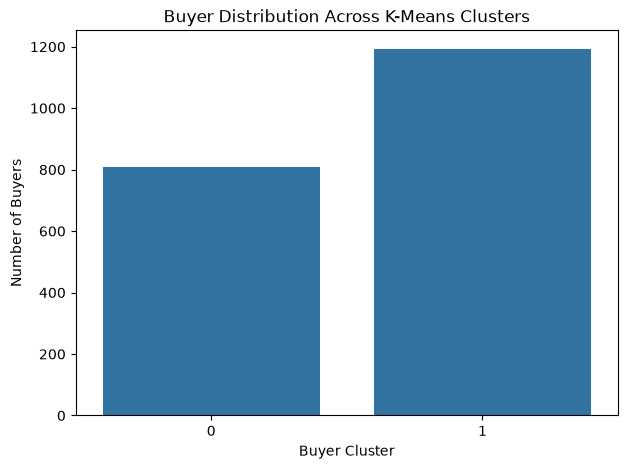

In [25]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=buyer_data,
    x="KMeans_Cluster"
)

plt.title("Buyer Distribution Across K-Means Clusters")
plt.xlabel("Buyer Cluster")
plt.ylabel("Number of Buyers")
plt.show()

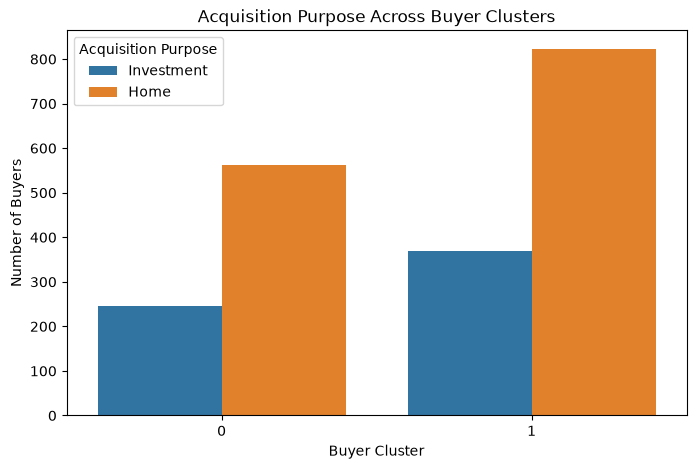

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=buyer_data,
    x="KMeans_Cluster",
    hue="acquisition_purpose"
)

plt.title("Acquisition Purpose Across Buyer Clusters")
plt.xlabel("Buyer Cluster")
plt.ylabel("Number of Buyers")
plt.legend(title="Acquisition Purpose")
plt.show()

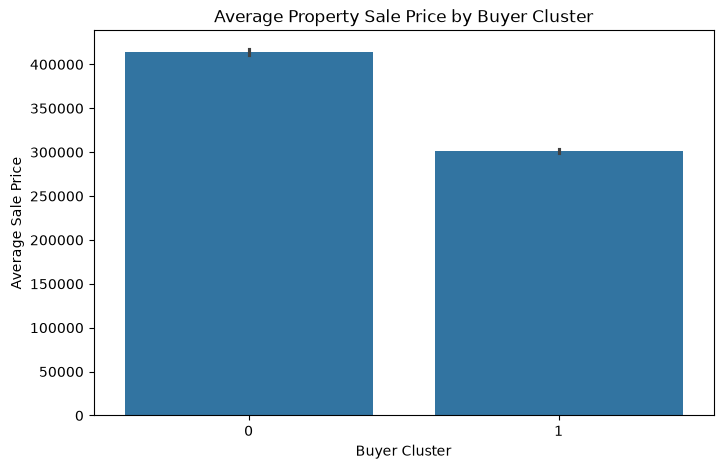

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=buyer_data,
    x="KMeans_Cluster",
    y="average_sale_price"
)

plt.title("Average Property Sale Price by Buyer Cluster")
plt.xlabel("Buyer Cluster")
plt.ylabel("Average Sale Price")
plt.show()

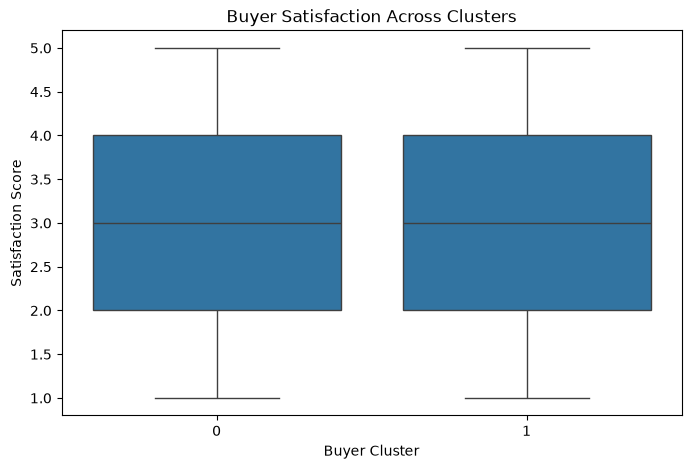

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=buyer_data,
    x="KMeans_Cluster",
    y="satisfaction_score"
)

plt.title("Buyer Satisfaction Across Clusters")
plt.xlabel("Buyer Cluster")
plt.ylabel("Satisfaction Score")
plt.show()